# Project 05: House Price Prediction\n## Notebook 01: EDA and Advanced Imputation

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
import os

# Create folders if not exists
os.makedirs('../models', exist_ok=True)
os.makedirs('../charts', exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

# Load the dataset (Ames Housing)
train = pd.read_csv('../data/raw/train.csv')
print(f"Dataset Shape: {train.shape}")
train.head()


Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 2. Target Transformation (Log-Scaling)

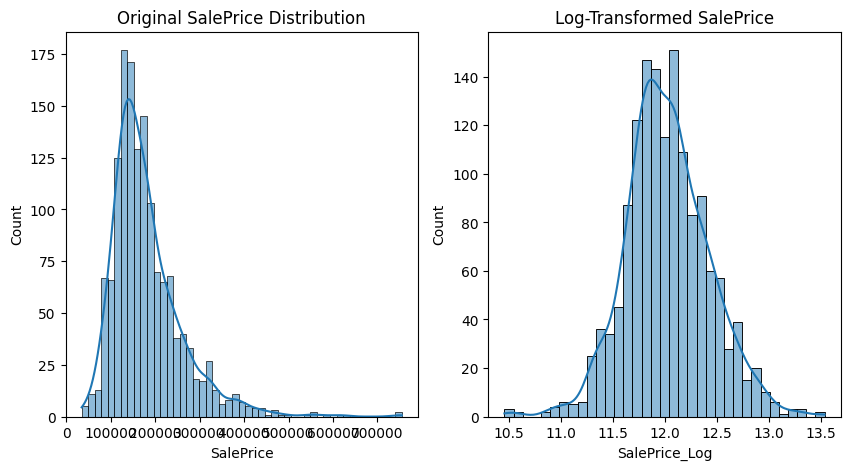

In [2]:

# SalePrice is typically highly right-skewed.
# We apply log-transformation to normalize the distribution for regression models.
plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
sns.histplot(train['SalePrice'], kde=True)
plt.title('Original SalePrice Distribution')

train['SalePrice_Log'] = np.log1p(train['SalePrice'])

plt.subplot(1, 2, 2)
sns.histplot(train['SalePrice_Log'], kde=True)
plt.title('Log-Transformed SalePrice')
plt.savefig('../charts/target_distribution.png')
plt.show()


### 3. Professional Multi-Strategy Imputation

In [3]:

# Identified 19 features with missing values. 
# Each requires a unique clinical/domain treatment.

# A. Categorical features where NA means "None"
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType', 'MSSubClass']

for col in none_cols:
    if col in train.columns:
        train[col] = train[col].fillna('None')

# B. Numerical features where NA means 0
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 
             'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 
             'BsmtHalfBath', 'MasVnrArea']

for col in zero_cols:
    if col in train.columns:
        train[col] = train[col].fillna(0)

# C. LotFrontage: Impute with median of the Neighborhood
train["LotFrontage"] = train.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median()))

# D. Mode imputation for essential features
mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType']
for col in mode_cols:
    if col in train.columns:
        train[col] = train[col].fillna(train[col].mode()[0])

# Functional is 'Typ' (typical) unless specified
train["Functional"] = train["Functional"].fillna("Typ")

print("Imputation Complete. Remaining Nulls:", train.isnull().sum().sum())


Imputation Complete. Remaining Nulls: 0


### 4. Numerical Skewness Handling and Final Save

In [4]:

# Identify numerical features with skewness > 0.75 and apply log(1+x)
numeric_feats = train.dtypes[train.dtypes != "object"].index
skewed_feats = train[numeric_feats].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
skewness = pd.DataFrame({'Skew' :skewed_feats})

high_skew = skewness[abs(skewness) > 0.75].index
for feat in high_skew:
    if feat != 'SalePrice' and feat != 'SalePrice_Log':
        train[feat] = np.log1p(train[feat])

# Save processed data
train.to_csv('../data/processed/train_cleaned.csv', index=False)
print("Data saved to ../data/processed/train_cleaned.csv")


Data saved to ../data/processed/train_cleaned.csv
